# 10.3.1 Poço simples

Poço vertical de 2048 m (5 in), modelo de mistura a 3 equações (Beggs & Brill,
padrão intermitente), vértice de entrada com especificação de **reservatório**
(170 bar, IPL = 0.71 kg/s/bar, IPG = 0.042 kg/s/bar) e vértice de saída com
**válvula choke** (Cv = 30) a 10 bar. Diferenças finitas centrais, 25 nós.

Cenário: choke 100 % → 25 % em rampa (60–90 s), 25 % constante até 500 s,
25 % → 100 % (500–530 s). Figuras 10.32 a 10.34.

Nota: o arquivo original gravou o duto com padrão estratificado, mas o estado
inicial gravado só é estacionário com padrão intermitente (como diz o texto da
tese); o caso é carregado com essa correção. A integração original usou
tolerância relativa 0.1, por isso há diferenças visíveis nos transientes.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from mfsim.notebook_utils import describe, run_case, compare_states, show_pipe, plot_elements, plot_vertices

describe("10.3.1")
case, raw, res = run_case("10.3.1")
compare_states(res, raw)

10.3.1 Poço simples
Poço vertical de 2048 m (5 in), modelo a 3 equações (intermitente), reservatório (170 bar, IPL 0.71, IPG 0.042 kg/s/bar) e choke (Cv=30) com rampa 100%->25% (60-90 s) e 25%->100% (500-530 s).
Figuras da tese: Figs. 10.32-10.34


[implicit BDF] steps=481 rejected=32 rhs=6629 jac=198 | 3.5s
tempo de CPU: 3.55 s
duto modelo       var      máx |dif|   faixa MATLAB  dif/faixa
   1 beggs_brill  PT        5.38e-03       1.36e+00   3.94e-03
   1 beggs_brill  qL        1.34e+00       1.88e+01   7.12e-02
   1 beggs_brill  qG        1.36e-01       9.69e-01   1.40e-01


## Figura 10.32 - Variáveis do trecho de tubulação

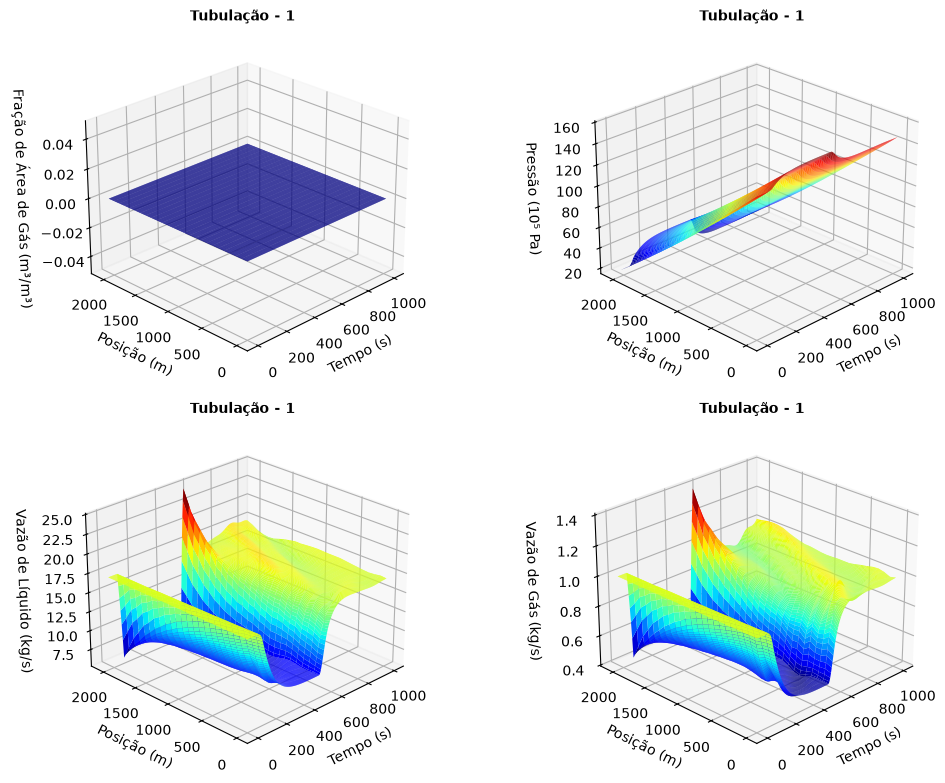

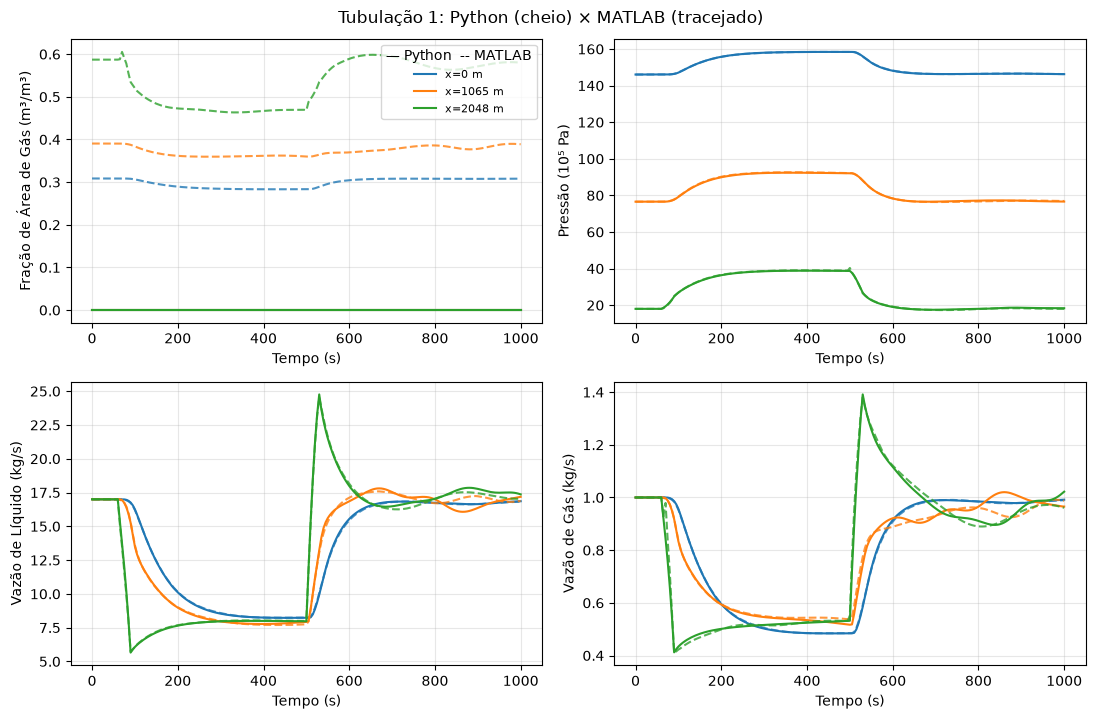

In [2]:
show_pipe(res, raw, 0)

## Figuras 10.33 e 10.34 - Válvula e reservatório

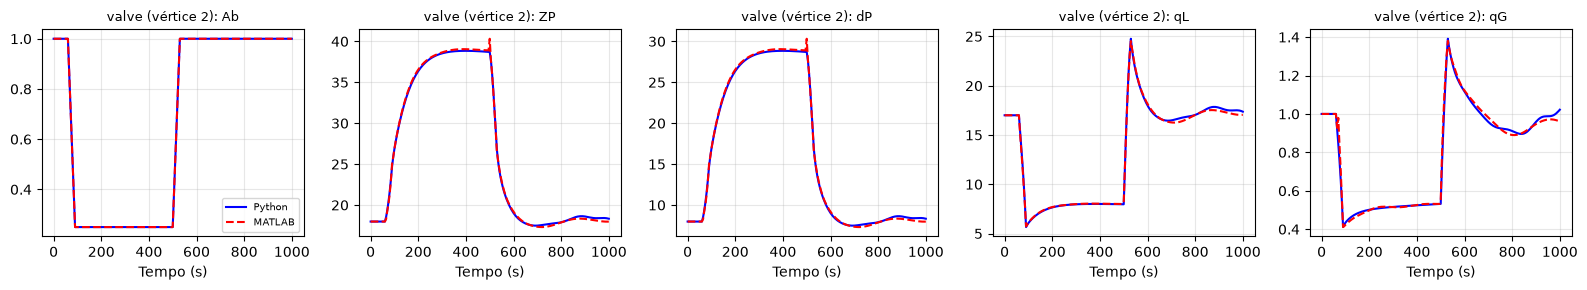

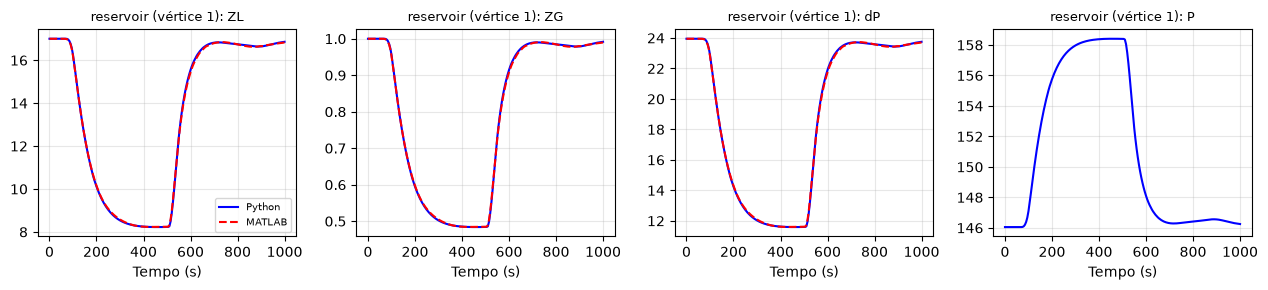

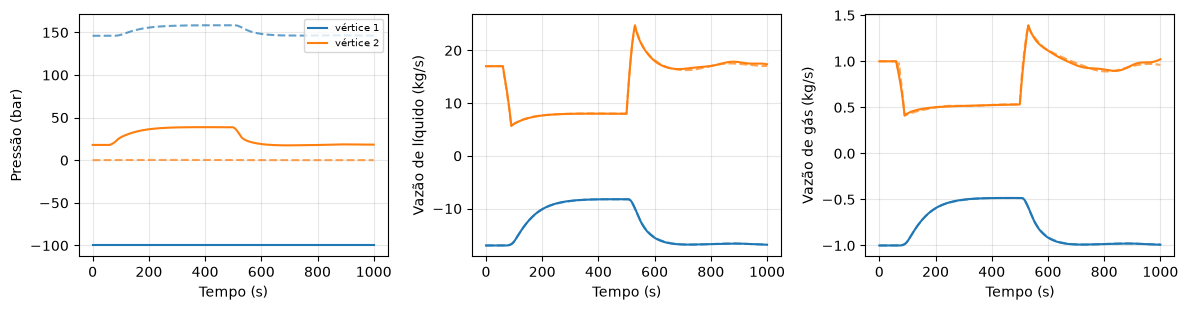

In [3]:
plot_elements(res, raw)
plot_vertices(res, raw)

## Lado direito compilado (JAX)
A mesma simulação com `simulate(..., jax=True)`: lado direito compilado por
`jax.jit` e Jacobiana exata por diferenciação automática (`mfsim/compiled.py`, o mesmo código numpy com o backend JAX),
no lugar das diferenças finitas coloridas. O resultado deve coincidir com a versão
numpy dentro da tolerância do integrador (as sequências de passos podem diferir
porque a Jacobiana muda o Newton); o ganho de tempo cresce com o número de passos
e de Jacobianas.

In [4]:
from mfsim.notebook_utils import jax_comparison
res_jax = jax_comparison(case, res, rtol=1e-4, atol=1e-6)

JAX: 0.89 s (418 passos; compilação 0.73 s, uma vez por modelo) | numpy: 3.55 s (481 passos) | diferença máxima relativa dos estados 1.0e-01


## Volume finito escalonado para o modelo de deriva

O esquema escalonado de volumes finitos (`method="fv_upwind"`, modo conservativo),
desenvolvido para o modelo a dois fluidos, foi estendido ao modelo de deriva:
hold-up e pressão nas células (equações de massa das duas fases, balanço exato),
vazões das fases nas faces, momento da mistura da tese para a soma e a relação de
escorregamento HG_BB(P, qL, qG) = HG da face imposta na forma diferenciada no
tempo com estabilização de Baumgarte (sem DAE, sem matriz de massa, sem inverter a
correlação). Abaixo, o mesmo cenário de fechamento e reabertura do choke com os
dois esquemas, partindo cada um do seu próprio estado estacionário; o esquema
nodal é o da tese (diferenças centrais).

volume finito: 333 passos em 2.9 s


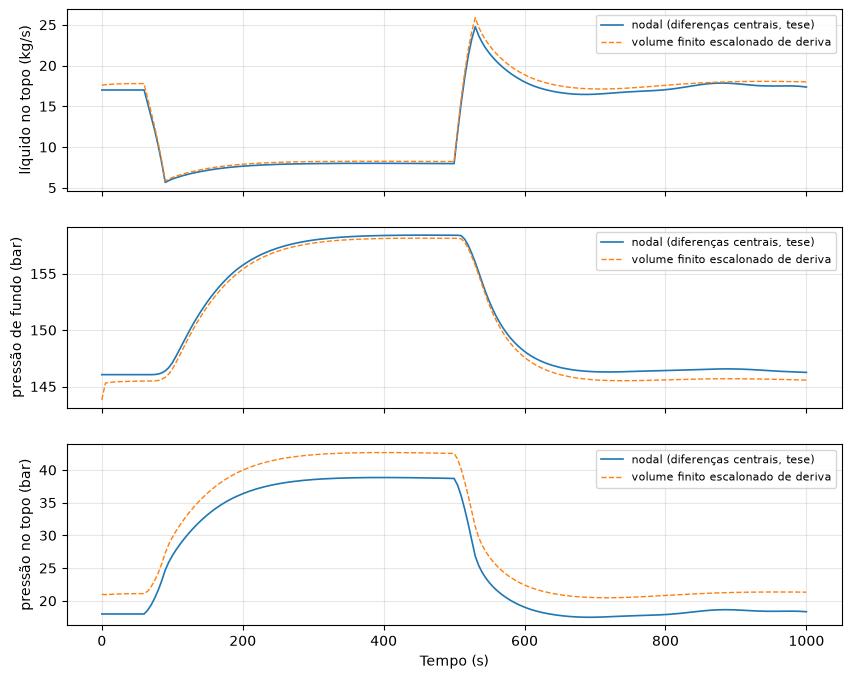

In [5]:
import copy, time
from mfsim.simulation import simulate, steady_state

case_fv = copy.deepcopy(case)
case_fv.settings.method = "fv_upwind"
case_fv.pipes[0].extra.update({"conservative": True, "q_switch": 0.05})
t0_ = time.time()
steady_state(case_fv, verbose=False, update_case=True)
res_fv = simulate(case_fv, progress=False, integrator="implicit", rtol=1e-3, atol=1e-6)
print(f"volume finito: {res_fv.info.get('n_steps')} passos em {time.time() - t0_:.1f} s")
p_n, p_f = res.pipe(0), res_fv.pipe(0)
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for p_, lab, st in ((p_n, "nodal (diferenças centrais, tese)", dict(lw=1.2)), (p_f, "volume finito escalonado de deriva", dict(lw=1.0, ls="--"))):
    top = -1 if p_ is p_n else -2            # no escalonado o último nó é o fantasma da válvula
    axes[0].plot(res.T if p_ is p_n else res_fv.T, p_["out"]["qL"][-1], label=lab, **st)
    axes[1].plot(res.T if p_ is p_n else res_fv.T, p_["out"]["P_bar"][0 if p_ is p_n else 1], label=lab, **st)
    axes[2].plot(res.T if p_ is p_n else res_fv.T, p_["out"]["P_bar"][top], label=lab, **st)
axes[0].set_ylabel("líquido no topo (kg/s)"); axes[1].set_ylabel("pressão de fundo (bar)"); axes[2].set_ylabel("pressão no topo (bar)"); axes[2].set_xlabel("Tempo (s)")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

As duas discretizações dão o mesmo transiente (picos de líquido na reabertura,
queda de pressão de fundo com o choke fechado); a pressão "no topo" do escalonado
é a da última célula, 41 m abaixo da válvula, por isso fica ~2 bar acima da nodal.
O escalonado conserva a massa de cada fase exatamente (acumulador consistente com
o BDF; ver `tests/test_fv_drift.py`), o que o esquema nodal não faz.